# AI500: Foundations of Artificial Intelligence
## Assignment 1, Section 2

---

### Overview
This notebook contains the programming portion of Assignment 1. You will translate foundational mathematical concepts, spanning linear algebra, probability, optimization, and algorithmic complexity, into Python code.

### Instructions
1. Write your code strictly within the designated `### YOUR CODE HERE ###` blocks.
2. Do not modify any of the provided setup code, dataset arrays, or assert statements.
3. Ensure all cells run sequentially without errors prior to submission.

### Student Information
Before proceeding to the problems, please assign your full name and student ID number to the variables below.

In [1]:
# Replace the empty strings with your actual name and student ID
student_name = "Muhammad Abdullah Naeem"
student_id = "26280047"

# --- Do not modify below this line ---
assert len(student_name) > 0, "Error: Please enter your full name."
assert len(student_id) == 8, "Error: Student ID must be exactly 8 characters long in the format 2X28XXXX"

print(f"Student Name: {student_name}")
print(f"Student ID: {student_id}")

Student Name: Muhammad Abdullah Naeem
Student ID: 26280047


---
### Environment Setup
Run the following cell to import the necessary libraries required for the four problems in this notebook.

In [2]:
import numpy as np
import time
import matplotlib.pyplot as plt

print("Libraries imported successfully. You may now proceed to Problem 1.")

Libraries imported successfully. You may now proceed to Problem 1.


## Problem 1: Forward Pass of an MLP

In this problem, you will manually trace the forward pass of a Multi-Layer Perceptron (MLP) containing **one hidden layer**.

To compute a neural network's predictions, we use matrix operations. For any given layer, the linear transformation is defined as:
$$z = W \cdot x + b$$
where $W$ is the weight matrix, $x$ is the input vector, and $b$ is the bias vector.

### 1. Matrix Calculations in NumPy
In Python, we use the `numpy` library to efficiently handle linear algebra. To multiply matrices and vectors, you can use the `np.dot()` function. Run the cell below to see a quick example.

In [3]:
# --- Tutorial: NumPy Matrix Calculation ---
example_input = np.array([1.0, 2.0])
example_weights = np.array([[0.5, -0.2],
                            [0.1,  0.8]])
example_bias = np.array([0.1, -0.1])

# Matrix multiplication: (W * x) + b
linear_output = np.dot(example_weights, example_input) + example_bias

print(f"Example Linear Output: {linear_output}")

Example Linear Output: [0.2 1.6]


### 2. Activation Functions
After the linear transformation, we apply a non-linear activation function to the resulting vector.

* **ReLU (Rectified Linear Unit):** Used for the hidden layer. It outputs the input directly if it is positive; otherwise, it outputs zero.
  $$f(x) = \max(0, x)$$
* **Sigmoid:** Used for the final output layer to squash the output into a probability between 0 and 1.
  $$\sigma(x) = \frac{1}{1 + e^{-x}}$$

### Your Task:
1. Complete the `relu(x)` function in the cell below. (Hint: Look up `np.maximum()`).
2. Calculate the linear output of the hidden layer (`z1`).
3. Apply your `relu` function to get the hidden layer's activation (`a1`).
4. Calculate the linear output of the final layer (`z2`) using `a1` as its input.
5. Apply the provided `sigmoid` function to get the network's `final_output`.

In [4]:
def sigmoid(x):
    """Applies the sigmoid activation function."""
    return 1 / (1 + np.exp(-x))

def relu(x):
    """Applies the ReLU activation function."""
    ### YOUR CODE HERE###
    return np.maximum(0, x)
    ### END CODE ###

# Input vector (3 features)
x = np.array([0.5, -1.2, 3.0])

# Hidden Layer 1 (4 neurons)
W1 = np.array([[ 0.2, -0.5,  0.1],
               [-0.4,  0.8, -0.2],
               [ 0.6,  0.1, -0.3],
               [-0.1, -0.2,  0.9]])
b1 = np.array([0.1, -0.1, 0.2, 0.0])

# Output Layer (1 neuron)
W2 = np.array([[0.5, -0.6, 0.3, -0.1]])
b2 = np.array([-0.2])

# Step 1: Calculate the linear output of the hidden layer (z1)

### YOUR CODE HERE ###
z1 = np.dot(W1, x) + b1
### END CODE ###

# Step 2: Apply the ReLU activation to z1 to get a1

### YOUR CODE HERE ###
a1 = relu(z1)
### END CODE ###

# Step 3: Calculate the linear output of the output layer (z2)

### YOUR CODE HERE ###
z2 = np.dot(W2, a1) + b2
### END CODE ###

# Step 4: Apply the Sigmoid activation to z2

### YOUR CODE HERE ###
final_output = sigmoid(z2)
### END CODE ###

# --- Do not modify below this line ---
print(f"Hidden Layer Activation (a1): {a1}")
print(f"Final Network Output: {final_output}")

Hidden Layer Activation (a1): [1.1  0.   0.   2.89]
Final Network Output: [0.51524527]


## Problem 2: Bayes' Theorem

In this problem, you will implement the core mathematical logic behind a Naive Bayes text classifier. Specifically, you will use Bayes' Theorem to determine the probability that an email is spam, given that it contains the word **"urgent"**.

Bayes' Theorem is defined as:
$$P(A \mid B) = \frac{P(B \mid A) \cdot P(A)}{P(B)}$$

Adapted for our spam classifier, the formula becomes:
$$P(\text{Spam} \mid \text{"urgent"}) = \frac{P(\text{"urgent"} \mid \text{Spam}) \cdot P(\text{Spam})}{P(\text{"urgent"})}$$

### The Law of Total Probability
To find the denominator $P(\text{"urgent"})$ (the total probability of seeing the word "urgent" in any email), you must combine the probability of seeing it in spam emails and non-spam emails:
$$P(\text{"urgent"}) = P(\text{"urgent"} \mid \text{Spam}) \cdot P(\text{Spam}) + P(\text{"urgent"} \mid \text{Not Spam}) \cdot P(\text{Not Spam})$$

### Your Task:
1. Calculate the prior probability of spam, $P(\text{Spam})$, and not spam, $P(\text{Not Spam})$ from the provided dataset statistics.
2. Calculate the total probability of the word "urgent" appearing, $P(\text{"urgent"})$.
3. Use Bayes' Theorem to calculate the posterior probability: $P(\text{Spam} \mid \text{"urgent"})$.

In [5]:
# --- Provided Dataset Statistics ---
total_emails = 10000
spam_emails = 2000
not_spam_emails = 8000

# Conditional probabilities (given from historical data)
# P("urgent" | Spam)
p_urgent_given_spam = 0.80

# P("urgent" | Not Spam)
p_urgent_given_not_spam = 0.05

# Step 1: Calculate Prior Probabilities

### YOUR CODE HERE ###
p_spam = spam_emails / total_emails
p_not_spam = not_spam_emails / total_emails
### END CODE ###

# Step 2: Calculate the total probability of seeing the word "urgent" (Evidence)

### YOUR CODE HERE ###
p_urgent = p_urgent_given_spam * p_spam + p_urgent_given_not_spam * p_not_spam
### END CODE ###

# Step 3: Calculate the posterior probability using Bayes' Theorem

### YOUR CODE HERE ###
p_spam_given_urgent = (p_urgent_given_spam * p_spam) / p_urgent
### END CODE ###

# --- Do not modify below this line ---
print(f"P(Spam): {p_spam}")
print(f"P(Not Spam): {p_not_spam}")
print(f"P('urgent'): {p_urgent}")
print(f"P(Spam | 'urgent'): {p_spam_given_urgent:.4f}")

P(Spam): 0.2
P(Not Spam): 0.8
P('urgent'): 0.20000000000000004
P(Spam | 'urgent'): 0.8000


## Problem 3: Algorithmic Complexity & Scalability in AI: Vocabulary Lookup

In Natural Language Processing (NLP) and Large Language Models (LLMs), tokenizers and embedding layers must map words or subword tokens to IDs in real time across vocabularies containing tens or hundreds of thousands of entries.

The data structure chosen to store and search this vocabulary directly dictates inference latency:
* **List (Sequential Search):** Searching an unordered list element-by-element takes linear time, $O(N)$ in the worst case, as every item must be inspected.
* **Hash Set / Dictionary (Hash-Based Lookup):** A hash table computes a hash code for the key, providing an average lookup time of $O(1)$ regardless of vocabulary size.

---

### Your Task:
You have been provided with a list of vocabulary sizes and two empty lists to store your timing results. Write a loop to benchmark the lookup times.

For every `size` in `vocab_sizes`:
1. Generate a synthetic vocabulary list using a list comprehension: `[f"token_{i}" for i in range(size)]`.
2. Create a Python `set` from that list.
3. Define your search target as the very last token in that sequence: `f"token_{size - 1}"`.
4. Start a timer using `time.perf_counter()`, search for the target in the **list**, stop the timer, and append the elapsed time to `list_search_times`.
5. Repeat the timing process for the **set**, appending the elapsed time to `set_search_times`.

Once your loop finishes, the provided code at the bottom will automatically plot your results.

N =  10,000 | list: 0.00016253s | set: 0.00000271s
N =  50,000 | list: 0.00096697s | set: 0.00000322s
N = 100,000 | list: 0.00204393s | set: 0.00000336s
N = 250,000 | list: 0.00582067s | set: 0.00000414s
N = 500,000 | list: 0.00985245s | set: 0.00000308s


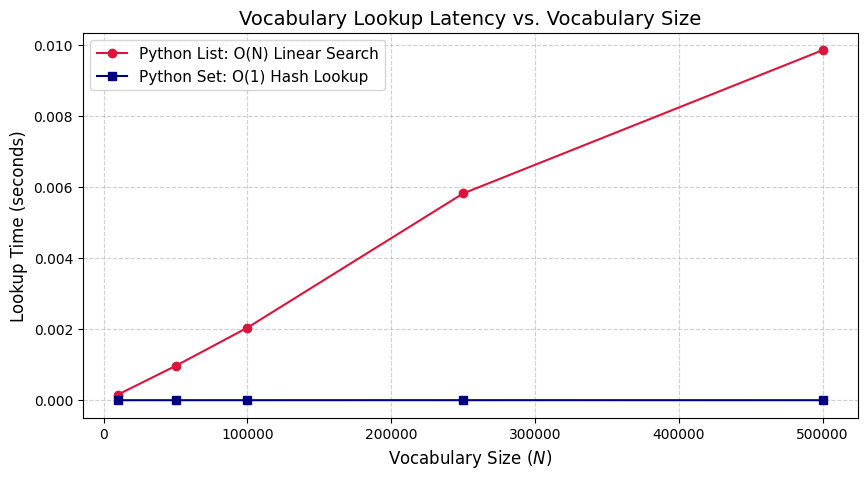

In [6]:
# Vocabulary sizes to test
vocab_sizes = [10_000, 50_000, 100_000, 250_000, 500_000]

list_search_times = []
set_search_times = []

### YOUR CODE HERE ###

# Write your for-loop, data generation, and timing logic below.

for size in vocab_sizes:
    vocab_list = [f"token_{i}" for i in range(size)]
    vocab_set = set(vocab_list)
    target = f"token_{size - 1}"

    start = time.perf_counter()
    found_in_list = target in vocab_list
    end = time.perf_counter()
    list_search_times.append(end - start)

    start = time.perf_counter()
    found_in_set = target in vocab_set
    end = time.perf_counter()
    set_search_times.append(end - start)

    print(f"N = {size:>7,} | list: {list_search_times[-1]:.8f}s | set: {set_search_times[-1]:.8f}s")

### END CODE ###

# ==========================================
#         Visualization (Plotting)
# ==========================================

plt.figure(figsize=(10, 5))
plt.plot(vocab_sizes, list_search_times, marker='o', label='Python List: O(N) Linear Search', color='crimson')
plt.plot(vocab_sizes, set_search_times, marker='s', label='Python Set: O(1) Hash Lookup', color='navy')

plt.title('Vocabulary Lookup Latency vs. Vocabulary Size', fontsize=14)
plt.xlabel('Vocabulary Size ($N$)', fontsize=12)
plt.ylabel('Lookup Time (seconds)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.show()

### Analysis & Reflection

Answer the following questions in 1–2 sentences each:
1. How do your plotted curves empirically confirm the theoretical time complexities of $O(N)$ for lists and $O(1)$ for hash sets?
2. While a hash set achieves near-instantaneous lookup times, what operational cost or trade-off does it introduce in a memory-constrained production environment?

**Answer**:

1. The list curve rises roughly in proportion to the vocabulary size so searching 500000 tokens costs about fifty times what searching 10000 tokens costs which is straight line through origin that O(n) predicts. because the target is the last elment and every entry must be compared. The set curve stays flat and stuck near the timer's resolution across the whole range, confirming that a hash lookup computes one hash and probes one bucket regardless of how large vocab has grown.

2. The set buys that speed with memory. It stores the same strings inside a sparsely populated hash table that is deliberately kept below full occupancy to avoid collisions so it occupies several times the footprint of the list. Also it pays a one-off construction cost to hash every token. In a memory constrained serving environment that overhead has to be weighed against alternatives like a sorted array with binary search, which give up some lookup speed in exchange for a much tighter and predictable memory profile

---
## Final Submission Check

Before downloading and submitting your assignment, you must ensure that your notebook runs from start to finish without any hidden state issues or errors.

**Please complete the following steps:**
1. Restart your environment and execute all cells from scratch:
   * **JupyterLab / Classic Notebook:** Select **Kernel > Restart & Run All** from the top menu.
   * **Google Colab:** Select **Runtime > Restart session and run all**.
   * **VS Code:** Click the **Restart** button (circular arrow) on the notebook toolbar, followed by the **Run All** button (double play icon).
2. Scroll through the entire notebook to verify that every cell executed successfully without throwing any exceptions.
3. Check that all required `print` statements, output variables, and the `matplotlib` plot are clearly visible.
4. Save your notebook.